<a href="https://colab.research.google.com/github/Mayureshnema04/Mayur786/blob/main/open_llms_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Open Source LLMs — a hands-on comparison

**A practical for the session "Open Source LLMs: Mistral, Llama, Qwen & Hugging Face".**

You will do three things:

1. **Check licence and size of a model *before* downloading it** (Step 2).
2. **Race three small open models** on the same questions and compare answer quality, speed and memory (Steps 3–6).
3. **Do the memory arithmetic** that tells you whether a model will fit on your hardware (Step 7).

Everything uses **free, openly licensed models**. No API key and no paid service are needed.
It runs on a normal Colab CPU runtime; a GPU (*Runtime → Change runtime type → T4 GPU*) only makes it faster.

> **Not a programmer?** You do not need to understand every line. Each cell starts with a comment block
> that tells you **what it does, what goes in, and what comes out**. Run the cells top to bottom and read the output.
> Steps 2 and 7 (licence check and "will it fit?") are the ones you would do by hand at work.

**How to run a cell:** click it, then press **Shift + Enter**. Run the cells in order, one at a time.

## Step 1 — Install and set up

Two cells: first install the libraries, then import them and check what hardware we have.

In [1]:
# WHAT : Installs the Python libraries (add-on toolkits) used in this notebook.
# INPUT : none
# OUTPUT: one confirmation message. (Colab may ask you to restart the runtime - if so, do it and re-run from the next cell.)

# transformers      -> loads and runs the language models
# huggingface_hub   -> asks the Hugging Face website about a model (licence, size)
# accelerate        -> lets the model choose GPU or CPU automatically
# torch             -> the maths engine the models run on
# pandas            -> neat tables;   matplotlib -> charts
%pip install -q "transformers>=5.0" "huggingface_hub>=1.0" accelerate torch pandas matplotlib

print("Install finished.")

Install finished.


In [2]:
# WHAT : Imports every library once, so later cells can simply use them. Also checks whether a GPU is available.
# INPUT : none
# OUTPUT: library version, and whether we run on "cpu" or "cuda" (= GPU).

import time                                   # a stopwatch, to measure how fast a model answers
import gc                                     # "garbage collector", to free memory after each model
import torch                                  # the engine that does the maths; also tells us if a GPU exists
import pandas as pd                           # tables (called DataFrames)
import matplotlib.pyplot as plt               # drawing charts
import transformers                           # Hugging Face library to run language models
from transformers import AutoTokenizer, AutoModelForCausalLM   # tokenizer = text<->numbers, model = the LLM itself
from huggingface_hub import HfApi             # reads model information from the Hugging Face Hub (website)

transformers.logging.set_verbosity_error()    # hide long, noisy warning messages

# Use the GPU if there is one, otherwise the CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("transformers version:", transformers.__version__)
print("running on          :", DEVICE)

transformers version: 5.18.0
running on          : cpu


## Step 2 — Licence and size, *before* you download

Every model on the Hugging Face Hub carries information: **licence**, **gated or not** (you must accept terms first),
**parameter count** (the model's "size") and **downloads**. We can read all of it **without downloading the model**.

In [3]:
# WHAT : Looks up licence, gated status, size and popularity for a list of models on Hugging Face - no download.
# INPUT : CANDIDATES = list of model names (format "owner/model-name").
# OUTPUT: a table with one row per model:
#           licence       -> what you are legally allowed to do (apache-2.0 / mit = very permissive)
#           gated         -> False = free to download; "manual"/"auto" = you must accept terms on the model page
#           params_B      -> size in billions of parameters
#           GB_fp16       -> memory needed to hold the model = parameters x 2 bytes
#           downloads_30d -> how popular / alive the model is

api = HfApi()   # our connection to the Hugging Face Hub

CANDIDATES = [
    "Qwen/Qwen3-0.6B",                          # models used later in this notebook
    "Qwen/Qwen2.5-0.5B-Instruct",
    "HuggingFaceTB/SmolLM2-360M-Instruct",
    "mistralai/Mistral-7B-Instruct-v0.3",       # other families, to show the licence variety
    "meta-llama/Llama-3.2-1B-Instruct",
    "google/gemma-3-270m-it",
    "microsoft/Phi-4-mini-instruct",
]

def hub_facts(repo_id):
    """Input: a model name.  Output: a dictionary with its licence, gated status, size and downloads."""
    try:
        info = api.model_info(repo_id)                  # ask the Hub (this is the only internet call)
    except Exception:
        return {"model": repo_id, "licence": "lookup failed (name may have changed)"}

    licence = info.card_data.license if info.card_data else None
    if isinstance(licence, list):                       # some models list several licences
        licence = ", ".join(licence)
    total = info.safetensors.total if info.safetensors else None   # total number of parameters

    return {
        "model": repo_id,
        "licence": licence or "not declared",
        "gated": info.gated or False,
        "params_B": round(total / 1e9, 2) if total else None,
        "GB_fp16": round(total * 2 / 1e9, 1) if total else None,   # fp16 = 2 bytes per parameter
        "downloads_30d": info.downloads,
    }

facts = pd.DataFrame([hub_facts(m) for m in CANDIDATES])   # one row per model -> table
facts                                                      # last line of a cell is displayed automatically

,model,licence,gated,params_B,GB_fp16,downloads_30d
0,Qwen/Qwen3-0.6B,apache-2.0,False,0.75,1.5,29469443
1,Qwen/Qwen2.5-0.5B-Instruct,apache-2.0,False,0.49,1.0,5793141
2,HuggingFaceTB/SmolLM2-360M-Instruct,apache-2.0,False,0.36,0.7,219538
3,mistralai/Mistral-7B-Instruct-v0.3,apache-2.0,False,7.25,14.5,1899299
4,meta-llama/Llama-3.2-1B-Instruct,llama3.2,manual,1.24,2.5,5072769
5,google/gemma-3-270m-it,gemma,manual,0.27,0.5,74284
6,microsoft/Phi-4-mini-instruct,mit,False,3.84,7.7,369692


**How to read the table**

* **licence** — `apache-2.0` and `mit` are permissive: commercial use is fine. Names like `llama3.2` or `gemma` are
  *custom* licences: usable, but with conditions you must read.
* **gated** — `manual` or `auto` means you must accept terms on the model's web page before downloading.
* **GB_fp16** — compare this with your computer's memory *before* you commit to a model.
* **downloads_30d** — a quick sign of whether the model is popular and maintained.

If a lookup fails, the model was probably renamed. Search for it on huggingface.co/models.

In [4]:
# WHAT : Turns a company rule ("we only allow certain licences") into an automatic PASS / BLOCK check.
# INPUT : a model name, and ALLOWED_LICENCES (the licences your company accepts).
# OUTPUT: prints PASS or BLOCK with the reason; returns True (OK to use) or False (not OK).

ALLOWED_LICENCES = {"apache-2.0", "mit", "bsd-3-clause"}   # edit this list to match your company policy

def can_i_ship(repo_id):
    facts = hub_facts(repo_id)                              # reuse the lookup from the previous cell
    problems = []
    if facts["licence"] not in ALLOWED_LICENCES:
        problems.append(f"licence '{facts['licence']}' is not on the allowed list")
    if facts.get("gated"):
        problems.append("model is gated - terms must be accepted first")

    print("PASS " if not problems else "BLOCK", repo_id, "; ".join(problems))
    return not problems

for model_name in ["Qwen/Qwen3-0.6B", "meta-llama/Llama-3.2-1B-Instruct", "google/gemma-3-270m-it"]:
    can_i_ship(model_name)

PASS  Qwen/Qwen3-0.6B 
BLOCK meta-llama/Llama-3.2-1B-Instruct licence 'llama3.2' is not on the allowed list; model is gated - terms must be accepted first
BLOCK google/gemma-3-270m-it licence 'gemma' is not on the allowed list; model is gated - terms must be accepted first


## Step 3 — Every model family formats a chat differently

Chat models were trained on conversations wrapped in special marker words (tokens), and **each family uses different markers**.
The *tokenizer* contains a **chat template** that wraps your text in exactly the format the model expects.
If you build the text by hand and get the format wrong, the model still replies — but quietly gets worse.

In [5]:
# WHAT : Shows how three different models wrap the SAME conversation in different special markers.
# INPUT : DEMO = a short conversation (a "system" instruction + a "user" question).
# OUTPUT: for each model, the exact text it would receive. Notice how different the three formats are.

DEMO = [
    {"role": "system", "content": "You are concise."},                    # instruction that sets the model's behaviour
    {"role": "user",   "content": "What is an open-weight model?"},       # the question
]

for name in ["Qwen/Qwen3-0.6B", "Qwen/Qwen2.5-0.5B-Instruct", "HuggingFaceTB/SmolLM2-360M-Instruct"]:
    tokenizer = AutoTokenizer.from_pretrained(name)       # downloads only the tiny tokenizer files
    text = tokenizer.apply_chat_template(
        DEMO,
        tokenize=False,               # give us readable text, not numbers
        add_generation_prompt=True,   # add the marker that says "now it is the assistant's turn"
    )
    print("#" * 70, "\n#", name, "\n" + "#" * 70)
    print(text, "\n")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (10 outputs left out)

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

###################################################################### 
# HuggingFaceTB/SmolLM2-360M-Instruct 
######################################################################
<|im_start|>system
You are concise.<|im_end|>
<|im_start|>user
What is an open-weight model?<|im_end|>
<|im_start|>assistant
 



## Step 4 — The comparison toolkit

Two small functions we reuse for the rest of the notebook:

* `load(name)` — downloads (first time only) and loads a model.
* `ask(...)` — asks a model one question and measures how long it took.

`ask(...)` switches Qwen3's "thinking" mode **off** by default so all models are compared fairly (Step 6 explores it).

`dtype="auto"` keeps the model's own number precision, and `device_map="auto"` puts the model on the GPU if there is one, otherwise the CPU.

In [6]:
# WHAT : Defines two helper functions. Nothing is downloaded or run yet - we only "teach" Python the helpers.
# INPUT : (when used later) load: a model name.   ask: tokenizer, model, a question.
# OUTPUT: load -> (tokenizer, model).   ask -> a dictionary: answer text, seconds taken, tokens/second.

def load(name):
    """Input: model name.  Output: its tokenizer and the model, ready to use."""
    tokenizer = AutoTokenizer.from_pretrained(name)
    model = AutoModelForCausalLM.from_pretrained(name, dtype="auto", device_map="auto")
    return tokenizer, model

def ask(tokenizer, model, question, max_new_tokens=160, thinking=False):
    """Input: tokenizer, model, question text, max length of the answer (in tokens),
              thinking (True = let Qwen3 reason step by step first; other models ignore it).
       Output: {"answer": text, "seconds": time taken, "tok_per_s": speed}.
       (A token is roughly 3/4 of a word.)"""
    messages = [
        {"role": "system", "content": "You are a helpful, concise assistant."},
        {"role": "user", "content": question},
    ]
    # 1) wrap the conversation in the model's chat format, then turn the text into numbers
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                           enable_thinking=thinking)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    # 2) let the model write the answer, and time it
    start = time.perf_counter()
    with torch.inference_mode():                         # "just answer, no training" = faster, less memory
        output = model.generate(**inputs,
                                max_new_tokens=max_new_tokens,
                                do_sample=False,         # always pick the most likely word -> same answer every run
                                pad_token_id=tokenizer.eos_token_id)
    seconds = time.perf_counter() - start

    # 3) keep only the NEW tokens (drop our own question) and turn them back into text
    new_tokens = output[0][inputs["input_ids"].shape[-1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return {"answer": answer, "seconds": seconds, "tok_per_s": len(new_tokens) / seconds}

print("Toolkit ready.")

Toolkit ready.


## Step 5 — The race

Four questions, each testing something different:

| Question | What it tests |
|---|---|
| factual | What the model memorised (small models are weak here) |
| instruction | Can it follow a strict output format? |
| structured | Can it produce valid JSON? |
| reasoning | Can it do a two-step calculation? |

Models are loaded **one at a time** and removed from memory afterwards, so this fits on a small machine.
Expect a few minutes on CPU; the first run also downloads about 2 GB.

In [7]:
# WHAT : Runs every model on every question; records speed, memory use and the answers.
# INPUT : MODELS = models to compare;  QUESTIONS = the four test questions (edit these freely).
# OUTPUT: a progress log while running, then a summary table `results` (size, memory, average speed).
#         All answers are saved in `answers` for the next cell.

MODELS = [
    "HuggingFaceTB/SmolLM2-360M-Instruct",
    "Qwen/Qwen2.5-0.5B-Instruct",
    "Qwen/Qwen3-0.6B",
]

QUESTIONS = {
    "factual":     "In one sentence: what does the Apache 2.0 licence permit?",
    "instruction": "List exactly three benefits of running a model locally. "
                   "Reply as three lines, each starting with '- '. No preamble.",
    "structured":  "Return ONLY valid JSON with keys 'name' and 'params_billions' "
                   "for a model called Qwen3-0.6B. No explanation.",
    "reasoning":   "A model has 7 billion parameters stored at 2 bytes each. "
                   "How many gigabytes is that? Answer with the number and one line of working.",
}

summary_rows = []   # one row per model (for the summary table)
answers = []        # one row per model + question (so we can read the answers later)

for name in MODELS:
    print(f"\n=== loading {name} ...")
    tokenizer, model = load(name)

    # Size of the model: count parameters, and the bytes they occupy in memory
    n_params = sum(p.numel() for p in model.parameters())
    n_bytes  = sum(p.numel() * p.element_size() for p in model.parameters())
    print(f"    {n_params / 1e9:.2f}B parameters, {n_bytes / 1e9:.2f} GB in memory")

    speeds = []
    for label, question in QUESTIONS.items():
        result = ask(tokenizer, model, question)
        speeds.append(result["tok_per_s"])
        answers.append({"model": name.split("/")[-1], "question": label, "answer": result["answer"]})
        print(f"    {label:<12} {result['seconds']:>5.1f} s   {result['tok_per_s']:>5.1f} tokens/s")

    summary_rows.append({
        "model": name.split("/")[-1],
        "params_B": round(n_params / 1e9, 2),
        "GB_in_memory": round(n_bytes / 1e9, 2),
        "avg_tokens_per_s": round(sum(speeds) / len(speeds), 1),
    })

    del model, tokenizer      # remove the model from memory before loading the next one
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

results = pd.DataFrame(summary_rows)
results


=== loading HuggingFaceTB/SmolLM2-360M-Instruct ...


model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

    0.36B parameters, 0.72 GB in memory
    factual        9.6 s     4.2 tokens/s
    instruction   10.2 s     2.4 tokens/s
    structured     9.5 s     3.0 tokens/s
    reasoning     10.1 s     4.0 tokens/s

=== loading Qwen/Qwen2.5-0.5B-Instruct ...


... (7 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

    0.60B parameters, 1.19 GB in memory
    factual        8.5 s     3.3 tokens/s
    instruction    8.5 s     2.8 tokens/s
    structured    11.3 s     3.2 tokens/s
    reasoning     26.2 s     4.4 tokens/s


,model,params_B,GB_in_memory,avg_tokens_per_s
0,SmolLM2-360M-Instruct,0.36,0.72,3.4
1,Qwen2.5-0.5B-Instruct,0.49,0.99,3.5
2,Qwen3-0.6B,0.60,1.19,3.4


In [8]:
# WHAT : Prints every model's answer, question by question, so you can judge quality yourself.
#        (Speed means nothing if the answer is wrong!)
# INPUT : `answers` and `QUESTIONS` from the previous cell.
# OUTPUT: for each question, the three models' answers one below the other.

for label, question in QUESTIONS.items():
    print("=" * 70)
    print("QUESTION:", question[:100])
    print("=" * 70)
    for row in answers:
        if row["question"] == label:
            print(f"[{row['model']}]\n{row['answer'][:600]}\n")

QUESTION: In one sentence: what does the Apache 2.0 licence permit?
[SmolLM2-360M-Instruct]
The Apache 2.0 licence permits the use, distribution, and modification of the Apache HTTP Server, but does not grant the right to use, distribute, or modify the Apache Web Server.

[Qwen2.5-0.5B-Instruct]
Apache 2.0 licenses allow for the free use and distribution of software with certain conditions, including limitations on modifications and redistribution.

[Qwen3-0.6B]
The Apache 2.0 License permits the use, modification, and distribution of the software in any combination, including for commercial purposes.

QUESTION: List exactly three benefits of running a model locally. Reply as three lines, each starting with '- 
[SmolLM2-360M-Instruct]
- Reduced carbon footprint and lower emissions
- Improved local economic growth and job creation
- Enhanced community engagement and social cohesion

[Qwen2.5-0.5B-Instruct]
- Reduced carbon footprint through local production.
- Enhanced sustainability by

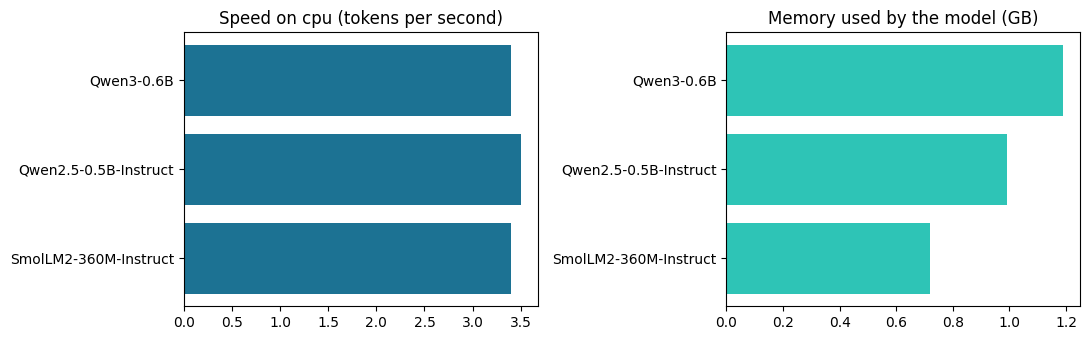

In [9]:
# WHAT : Draws two bar charts from the `results` table: speed and memory per model.
# INPUT : `results` from the race cell.
# OUTPUT: left chart = tokens per second (higher is faster); right chart = GB of memory (lower is lighter).

fig, (ax_speed, ax_memory) = plt.subplots(1, 2, figsize=(11, 3.5))   # two charts side by side

ax_speed.barh(results["model"], results["avg_tokens_per_s"], color="#1C7293")
ax_speed.set_title(f"Speed on {DEVICE} (tokens per second)")

ax_memory.barh(results["model"], results["GB_in_memory"], color="#2EC4B6")
ax_memory.set_title("Memory used by the model (GB)")

plt.tight_layout()
plt.show()

### 🧪 EXPERIMENT 1 — add a model you care about

Edit the `MODELS` list in the race cell and re-run it. Ideas (all permissive licences):

* `Qwen/Qwen3-1.7B` — one size up from Qwen3-0.6B
* `google/gemma-3-270m-it` — Google's smallest model
* `HuggingFaceTB/SmolLM3-3B` — about 6 GB, needs a bigger machine

Run `can_i_ship("model-name")` from Step 2 first. Llama models are *gated*: accept the licence on their Hugging Face page, then run
`from huggingface_hub import login; login()`.

Ask yourself: is the bigger model better **enough** to justify being slower and heavier?

## Step 6 — One model, two modes: Qwen3's "thinking" switch

Qwen3 can either **think step by step** before answering, or **answer directly**. It is the same model; only a flag in the chat template changes.
Thinking is more accurate on multi-step problems but produces many more tokens (= more waiting time).

In [10]:
# WHAT : Asks Qwen3 the same question with thinking OFF, then ON, and compares the answers and the time taken.
# INPUT : QUESTION (text);  thinking = False / True (a switch only Qwen3 understands; it is OFF in all other cells).
# OUTPUT: for each mode: how many tokens were produced, how long it took, and the answer text.
#         (With thinking ON you will see its reasoning inside <think> ... </think>; it may be cut off at 320 tokens.)

QUESTION = ("A 14B model is quantised from 16-bit to 4-bit. "
            "Roughly how many GB does it need afterwards? Give the number.")

tokenizer, model = load("Qwen/Qwen3-0.6B")

for thinking in (False, True):
    result = ask(tokenizer, model, QUESTION, max_new_tokens=320, thinking=thinking)
    print("=" * 70)
    print(f"thinking={thinking}   {result['seconds']:.1f} seconds")
    print("=" * 70)
    print(result["answer"][:1200], "\n")

del model, tokenizer     # free the memory
gc.collect()
print("Done.")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

thinking=False   6.6 seconds
Roughly 1 GB. 

thinking=True   69.5 seconds
<think>
Okay, let's see. The user is asking about how many GB a 14B model would need after quantising from 16-bit to 4-bit. Hmm, first, I need to understand what 14B means here. I think "14B" refers to the bit depth, so the model is quantised from 16-bit to 4-bit. 

Wait, quantisation is a process where you reduce the precision of the data. So, if the original model is 16-bit, and you quantise it down to 4-bit, that means you're reducing the number of bits. But how does that affect the storage required?

I remember that the storage required for a model depends on the number of bits. Each bit contributes to the storage. So, if you have 16 bits, each bit is 1/16th of a byte. But wait, when you quantise, you're reducing the number of bits, so the storage would decrease. But the question is about how many GB it needs afterwards. 

Wait, maybe I need to think about the bit depth and the storage in bytes. Let me check.

## Step 7 — Will it fit? The arithmetic that decides

```
memory for the model  ≈  number of parameters  ×  bytes per parameter
```

| precision | bytes per parameter |
|---|---|
| fp32 | 4 |
| fp16 / bf16 | 2 |
| int8 | 1 |
| 4-bit | 0.5 |

Add roughly 25% on top for the working memory used while generating text.

**The trap with Mixture-of-Experts (MoE) models:** you must size against the **total** parameters, not the "active" ones.
All experts must sit in memory, even if only a few are used per word. "41B active" does *not* mean a 41B-sized machine.

In [11]:
# WHAT : Calculates whether a model fits in your memory at four different precisions.
# INPUT : model size in billions of parameters, and your available memory in GB.
# OUTPUT: one line per precision: memory for the weights, memory with 25% extra, and "fits" / "does NOT fit".

BYTES_PER_PARAMETER = {"fp32": 4, "fp16": 2, "int8": 1, "4-bit": 0.5}

def fits(total_params_b, available_gb, overhead=1.25):
    print(f"\nModel: {total_params_b}B parameters   |   Available memory: {available_gb} GB")
    for precision, nbytes in BYTES_PER_PARAMETER.items():
        weights_gb = total_params_b * nbytes            # billions x bytes = GB
        needed_gb = weights_gb * overhead               # add 25% for working memory
        verdict = "fits" if needed_gb <= available_gb else "does NOT fit"
        print(f"  {precision:<6} weights {weights_gb:7.1f} GB   with overhead {needed_gb:7.1f} GB  ->  {verdict}")

# A free Colab T4 GPU has about 15 GB of memory
fits(0.6, 15)    # Qwen3-0.6B
fits(8, 15)      # a typical 8B model
fits(675, 15)    # Mistral Large 3: MoE with 41B "active" parameters, but all 675B must be held in memory


Model: 0.6B parameters   |   Available memory: 15 GB
  fp32   weights     2.4 GB   with overhead     3.0 GB  ->  fits
  fp16   weights     1.2 GB   with overhead     1.5 GB  ->  fits
  int8   weights     0.6 GB   with overhead     0.8 GB  ->  fits
  4-bit  weights     0.3 GB   with overhead     0.4 GB  ->  fits

Model: 8B parameters   |   Available memory: 15 GB
  fp32   weights    32.0 GB   with overhead    40.0 GB  ->  does NOT fit
  fp16   weights    16.0 GB   with overhead    20.0 GB  ->  does NOT fit
  int8   weights     8.0 GB   with overhead    10.0 GB  ->  fits
  4-bit  weights     4.0 GB   with overhead     5.0 GB  ->  fits

Model: 675B parameters   |   Available memory: 15 GB
  fp32   weights  2700.0 GB   with overhead  3375.0 GB  ->  does NOT fit
  fp16   weights  1350.0 GB   with overhead  1687.5 GB  ->  does NOT fit
  int8   weights   675.0 GB   with overhead   843.8 GB  ->  does NOT fit
  4-bit  weights   337.5 GB   with overhead   421.9 GB  ->  does NOT fit


Look at the last case: a 675B-total / 41B-active MoE runs at roughly the *speed* of a 41B model, but needs the *memory* of a 675B model
(about 1.35 TB at fp16, still ~340 GB at 4-bit). Sparsity buys speed, not a smaller machine.

### 🧪 EXPERIMENT 2 — build your own mini test set

Everything above is a demo. At work you would do this: write 10–20 questions from **your own domain**, note what a correct answer
must contain, and score each model. It turns "which model is better?" from an opinion into a measurement.

The cell below checks whether a required word appears in the answer. That is enough for short, checkable tasks (classification, extraction, JSON).

In [12]:
# WHAT : Scores each model with a mini test: a question + a word that MUST appear in a correct answer.
# INPUT : TEST_SET = list of (question, required word);  MODELS = models to test (from the race cell).
# OUTPUT: PASS / FAIL for every question and model, then a score such as 3/4.

TEST_SET = [
    ("Reply with exactly one word: the capital of France.",      "Paris"),
    ("Is 17 a prime number? Answer yes or no only.",             "yes"),
    ("Return ONLY the JSON {\"ok\": true} and nothing else.",   "ok"),
    ("What is 12 multiplied by 12? Digits only.",                "144"),
]

for name in MODELS:
    tokenizer, model = load(name)
    score = 0
    print(f"\n{name}")
    for question, required_word in TEST_SET:
        answer = ask(tokenizer, model, question, max_new_tokens=40)["answer"]
        passed = required_word.lower() in answer.lower()          # ignore capital letters
        score += passed                                           # True counts as 1, False as 0
        print(f"  [{'PASS' if passed else 'FAIL'}] {question[:50]:<50} -> {answer[:50]!r}")
    print(f"  score: {score}/{len(TEST_SET)}")

    del model, tokenizer
    gc.collect()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


HuggingFaceTB/SmolLM2-360M-Instruct
  [PASS] Reply with exactly one word: the capital of France -> 'Paris'
  [PASS] Is 17 a prime number? Answer yes or no only.       -> 'Yes.'
  [PASS] Return ONLY the JSON {"ok": true} and nothing else -> '{\n  "ok": true\n}'
  [PASS] What is 12 multiplied by 12? Digits only.          -> '12 multiplied by 12 equals 144.'
  score: 4/4


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


Qwen/Qwen2.5-0.5B-Instruct
  [PASS] Reply with exactly one word: the capital of France -> 'Paris'
  [PASS] Is 17 a prime number? Answer yes or no only.       -> 'Yes.'
  [PASS] Return ONLY the JSON {"ok": true} and nothing else -> '{"ok": true}'
  [PASS] What is 12 multiplied by 12? Digits only.          -> 'The result of multiplying 12 by 12 is 144.'
  score: 4/4


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


Qwen/Qwen3-0.6B
  [PASS] Reply with exactly one word: the capital of France -> 'Paris'
  [PASS] Is 17 a prime number? Answer yes or no only.       -> 'Yes.'
  [PASS] Return ONLY the JSON {"ok": true} and nothing else -> '{"ok": true}'
  [FAIL] What is 12 multiplied by 12? Digits only.          -> '12'
  score: 3/4


## Where to go next

* **Quantise it** — load the model in 4-bit (`BitsAndBytesConfig`) to cut memory about four times on a GPU.
* **Serve it** — `transformers serve` gives an OpenAI-compatible endpoint; for real traffic use vLLM or SGLang.
* **Run it outside Python** — convert to GGUF and use Ollama or llama.cpp (light, works well on CPU and Apple silicon).
* **Fine-tune it** — LoRA on a 0.5B–3B model is cheap, and it is something a paid API cannot give you.

### Three things to remember

1. **Open weights is not the same as open source.** Always check the licence field.
2. **Licence and hardware are stable constraints; leaderboards change.** Choose on the stable ones.
3. **Total parameters decide the machine you need; active parameters decide the speed.** Size against the total.